In [1]:
import numpy as np
import csv
import astropy.io
from astropy.io import fits
from astropy.table import Table
import warnings
warnings.filterwarnings("ignore")
import lightkurve as lk
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from pathlib import Path
from astropy.io import ascii

In [291]:
#---- Settings ----
CATALOG = Path("student_catalog.csv") # path to your catalog
LC_DIR  = Path("lightcurves-cmn")     # folder the download script filled
# which source: row index from the catalog (1-based, “index” column)
N = 1

#1) Look up the star in the catalog by its index
with open(CATALOG, newline="") as f:
    rows = list(csv.DictReader(f))
row = next(r for r in rows if int(r["index"]) == N)
bonus_id = row["kepler_bonus_id"]
#print("Using:", row["gaia_id"], "|", bonus_id)

#2) Build the filename exactly as the download script does
fname = f"hlsp_kbonus-bkg_kepler_kepler_{bonus_id}_kepler_v1.0_lc.fits"
path = LC_DIR / fname

#3) Read the FITS file into a table with the column names G_code expects
with fits.open(path) as hdul:
    tab = hdul["LIGHTCURVE_STITCHED"].data
    #print("Columns:", tab.names)              # check the error column name here
    bkjd = np.array(tab["TIME"], dtype=float)
    sap  = np.array(tab["SAP_FLUX"], dtype=float)
    err  = (np.array(tab["SAP_FLUX_ERR"], dtype=float) if "SAP_FLUX_ERR" in tab.names
            else np.array(tab["FLUX_ERR"], dtype=float) if "FLUX_ERR" in tab.names
            else np.full_like(sap, np.nanstd(sap)))       # fallback if no error column

data = Table({"BKJD": bkjd, "SAP_FLUX": sap, "FLUX_ERR": err})

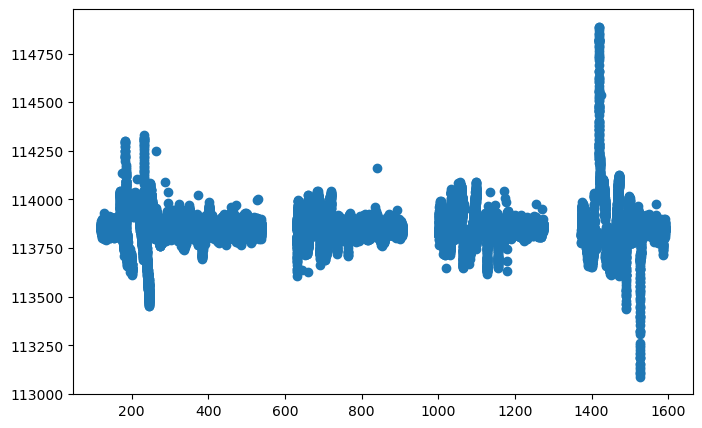

In [292]:
plt.figure(figsize=(8, 5))
plt.scatter(data['BKJD'], data['SAP_FLUX'])

plt.show()

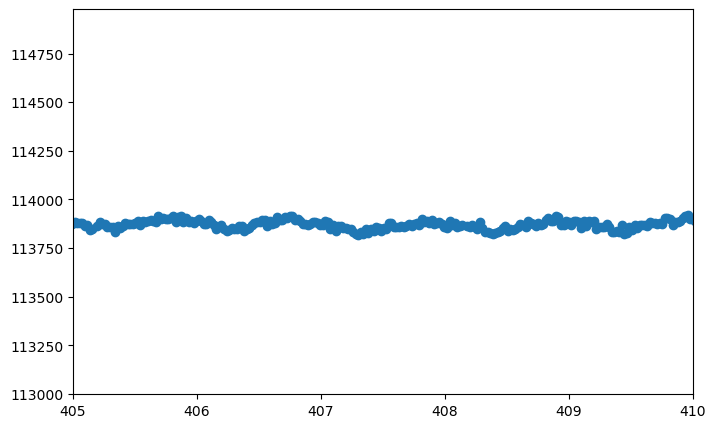

In [293]:
plt.figure(figsize=(8, 5))
plt.scatter(data['BKJD'], data['SAP_FLUX'])

plt.xlim(405, 410)
plt.show()

`period` contains 360374 points.Periodogram is likely to be large, and slow to evaluate. Consider setting `frequency_factor` to a higher value.


period = 27.2510 d, T0 = 136.659 BKJD, duration ~ 0.40 d
F_0      = 0.999999 +/- 0.000017
C        = 0.000423 +/- 0.000062
theta_0  = 0.202685 +/- 0.101171
theta_1  = 0.554796 +/- 0.151553
theta_2  = 0.186327 +/- 0.067395
transit depth ~ 241 ppm


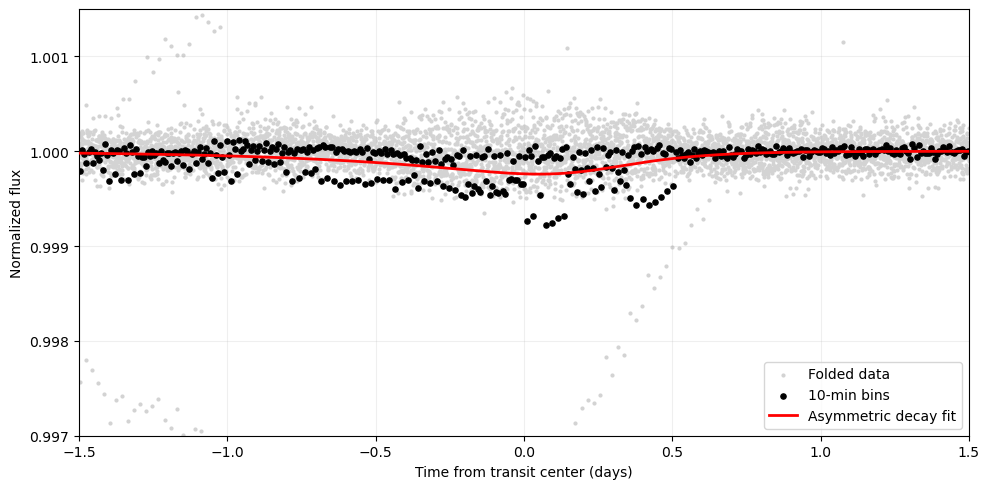

In [294]:
# ---- Cell 4 (lightkurve version): clean, find period, fold, and fit the transit ----
# Assumes `data` (cell 1) and the imports (cell 0) have already run.
import astropy.units as u
from astropy.time import Time

def as_float(v):
    """Lightkurve sometimes returns Quantity/Time objects; turn them into plain floats."""
    return float(getattr(v, "value", v))

# 1) Build a LightCurve object (BKJD = Kepler barycentric JD - 2454833)
lc = lk.LightCurve(
    time=Time(np.array(data['BKJD'], dtype=float), format='bkjd', scale='tdb'),
    flux=np.array(data['SAP_FLUX'], dtype=float),
    flux_err=np.array(data['FLUX_ERR'], dtype=float),
)

# 2) Clean + normalize. Only clip *upward* aggressively so transit dips aren't removed.
lc = lc.remove_nans().normalize()
lc = lc.remove_outliers(sigma_upper=4, sigma_lower=10)

# 3) First-pass flatten (1.5 d window, i.e. ~73 cadences of ~0.02 d; must be odd),
#    just good enough to find the transit signal
window = 73
flat = lc.flatten(window_length=window, polyorder=2)

# 4) Box Least Squares period search
periods = np.arange(5, 30, 0.001)
bls = flat.to_periodogram(method='bls', period=periods, duration=[0.1, 0.2, 0.3, 0.4])
period = as_float(bls.period_at_max_power)
t0 = as_float(bls.transit_time_at_max_power)
duration = as_float(bls.duration_at_max_power)
print(f"period = {period:.4f} d, T0 = {t0:.3f} BKJD, duration ~ {duration:.2f} d")

# 5) Re-flatten with the transits masked so the filter doesn't eat the dip,
#    then fold on the period we found
mask = lc.create_transit_mask(period=period, transit_time=t0, duration=duration * 2)
flat = lc.flatten(window_length=window, polyorder=2, mask=mask)
folded = flat.fold(period=period, epoch_time=t0)

phase = np.asarray(folded.time.value, dtype=float)       # days from transit center
y_fold = np.asarray(folded.flux.value, dtype=float)      # normalized flux
keep = np.isfinite(phase) & np.isfinite(y_fold) & (np.abs(phase) < 1.5)
phase, y_fold = phase[keep], y_fold[keep]

# 6) Asymmetric hyperbolic secant transit model
def transit_model(x, F_0, C, theta_0, theta_1, theta_2):
    return F_0 - C * ((np.exp(-(x - theta_0) / theta_1) + np.exp((x - theta_0) / theta_2)) ** -1)

initial_guess = [1.0, 2e-3, 0.0, 0.1, 0.1]     # baseline, amplitude, center (d), widths (d)
popt, pcov = curve_fit(
    transit_model, phase, y_fold, p0=initial_guess,
    bounds=([0.999, 1e-5, -0.5, 0.005, 0.005],
            [1.001, 5e-2,  0.5, 1.000, 1.000]),
    maxfev=20000,
)
perr = np.sqrt(np.diag(pcov))
for name, v, e in zip(["F_0", "C", "theta_0", "theta_1", "theta_2"], popt, perr):
    print(f"{name:8s} = {v:.6f} +/- {e:.6f}")

x_fit = np.linspace(-1.5, 1.5, 2000)
y_fit = transit_model(x_fit, *popt)
print(f"transit depth ~ {(1 - y_fit.min()) * 1e6:.0f} ppm")

# 7) Bin the folded light curve (10-minute bins) so the dip stands out from the noise
binned = folded.bin(time_bin_size=10 * u.min).remove_nans()
bx = np.asarray(binned.time.value, dtype=float)
by = np.asarray(binned.flux.value, dtype=float)
sel = np.abs(bx) < 1.5
bx, by = bx[sel], by[sel]

# 8) Plot
fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(phase, y_fold, color="lightgray", s=4, zorder=1, label="Folded data")
ax.scatter(bx, by, color="black", s=14, zorder=2, label="10-min bins")
ax.plot(x_fit, y_fit, color="red", linewidth=2, zorder=3, label="Asymmetric decay fit")

ax.set_xlim(-1.5, 1.5)
ax.set_ylim(0.997, 1.0015)
ax.set_xlabel("Time from transit center (days)")
ax.set_ylabel("Normalized flux")
ax.legend()
ax.grid(True, alpha=0.2)
plt.tight_layout()
plt.show()